
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# Affine Maps of the Complex Plane

**Prerequisites:** [Complex Numbers](complex-numbers.ipynb)

Plane geometry can be done with complex arithmetic. Here every map has the form $f(z) = Az + B$ with $A, B \in \mathbb{C}$.

::: {#def-plane-motions}
## Translations, Rotations, Homotheties

Let $z_0, B \in \mathbb{C}$, $\alpha \in \mathbb{R}$, $k > 0$.

1. **Translation** by $B$: $\ z \mapsto z + B$.
2. **Rotation** by the angle $\alpha$ about $z_0$: $\ z \mapsto z_0 + \operatorname{cis}\alpha\,(z - z_0)$.
3. **Homothety** (dilation) with centre $z_0$ and ratio $k$: $\ z \mapsto z_0 + k(z - z_0)$.
:::

By [polar multiplication](complex-numbers.ipynb#thm-polar-product), $w \mapsto \operatorname{cis}\alpha\, w$ rotates the vector $w = z - z_0$ by $\alpha$ and $w \mapsto kw$ scales it, which justifies the names. Expanding, the rotation is $z \mapsto \operatorname{cis}\alpha\, z + (1 - \operatorname{cis}\alpha) z_0$ and the homothety is $z \mapsto kz + (1-k)z_0$.

::: {#thm-affine-classification}
## Classification of $z \mapsto Az + B$

Let $f(z) = Az + B$.

1. If $A = 0$, $f$ is constant.
2. If $A = 1$, $f$ is the translation by $B$.
3. If $A \ne 0, 1$, then $f$ has exactly one fixed point $z_0 = \dfrac{B}{1 - A}$, and with $A = k\operatorname{cis}\alpha$ ($k = |A|$),
$$f(z) = z_0 + A(z - z_0) = z_0 + k\big(\operatorname{cis}\alpha\,(z - z_0)\big):$$
the rotation by $\alpha$ about $z_0$ followed by the homothety of ratio $k$ about $z_0$ (the two commute). It is a rotation if and only if $|A| = 1$ and a homothety if and only if $A$ is real and positive.

Conversely every translation, rotation, homothety and composition of them has this form.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-affine-classification
(1), (2) are clear. (3): $f(z_0) = z_0 \iff Az_0 + B = z_0 \iff z_0 = B/(1-A)$, unique since $A \ne 1$. Then $f(z) - z_0 = f(z) - f(z_0) = A(z - z_0)$. Writing $A = k\operatorname{cis}\alpha$ gives the description, and $k\operatorname{cis}\alpha\, w = \operatorname{cis}\alpha\,(kw)$ shows the order does not matter. The converse: each of the three motions has the form $Az + B$ (expanded above), and $A_2(A_1 z + B_1) + B_2 = (A_2A_1) z + (A_2 B_1 + B_2)$. $\blacksquare$
:::

::: {#cor-compose-rotations}
## Composition of Two Rotations

Let $R_1(z) = \operatorname{cis}\alpha\, z + B_1$ and $R_2(z) = \operatorname{cis}\beta\, z + B_2$ be rotations. Then
$$R_2 \circ R_1(z) = \operatorname{cis}(\alpha + \beta)\, z + \operatorname{cis}\beta\, B_1 + B_2 .$$
If $\alpha + \beta \in 2\pi\mathbb{Z}$ this is a translation; otherwise it is the rotation by $\alpha + \beta$ about $\dfrac{\operatorname{cis}\beta\, B_1 + B_2}{1 - \operatorname{cis}(\alpha + \beta)}$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-compose-rotations
Compose and apply @thm-affine-classification with $A = \operatorname{cis}\alpha\operatorname{cis}\beta = \operatorname{cis}(\alpha + \beta)$, which equals $1$ exactly when $\alpha + \beta \in 2\pi\mathbb{Z}$. $\blacksquare$
:::

::: {#exm-affine}
## Examples

1. *Two quarter turns.* The rotation by $\frac{\pi}{2}$ about $1$ is $R_1(z) = i(z - 1) + 1 = iz + 1 - i$; about $-1$ it is $R_2(z) = iz + i - 1$. Then $R_2(R_1(z)) = -z + 2i$: the half turn about $i$.
2. *Two half turns make a translation.* The half turn about $a$ is $H_a(z) = 2a - z$, and $H_b \circ H_a(z) = z + 2(b - a)$.
3. *A spiral similarity.* $f(z) = (1 + i)z + 2$ has $A = \sqrt2\operatorname{cis}\frac{\pi}{4}$ and fixed point $z_0 = \frac{2}{1 - (1+i)} = 2i$: it rotates by $45^\circ$ about $2i$ and scales by $\sqrt{2}$.
:::

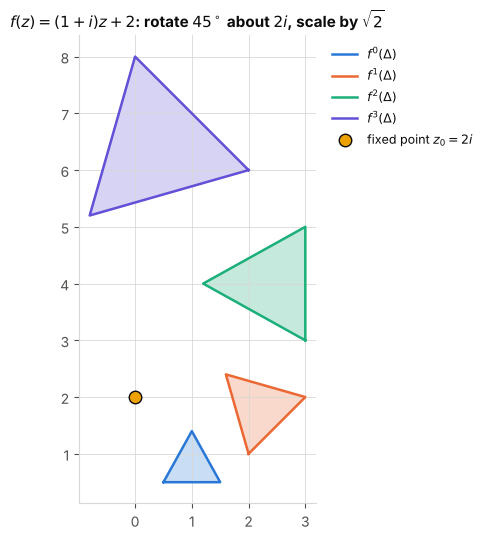

f(z0) == z0: True | z0 = (-0+2j)


In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

A, B = 1 + 1j, 2
f = lambda z: A * z + B
z0 = B / (1 - A)
tri = np.array([0.5 + 0.5j, 1.5 + 0.5j, 1.0 + 1.4j, 0.5 + 0.5j])

fig, ax = plt.subplots(figsize=(8, 5.5))
img = tri
for k, col in enumerate([BLUE, ORANGE, AQUA, VIOLET]):
    ax.fill(img.real, img.imag, color=col, alpha=0.25)
    ax.plot(img.real, img.imag, color=col, lw=1.8, label=f"$f^{{{k}}}(\\Delta)$")
    img = f(img)
ax.plot(z0.real, z0.imag, "o", color=YELLOW, ms=9, mec=INK, label=r"fixed point $z_0 = 2i$")
ax.set_aspect("equal"); ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
ax.set_title(r"$f(z) = (1+i)z + 2$: rotate $45^\circ$ about $2i$, scale by $\sqrt{2}$")
plt.tight_layout(); plt.show()
print("f(z0) == z0:", np.isclose(f(z0), z0), "| z0 =", z0)